First 5 rows:
   CustomerID Gender  Age   Education  Marital Status  Annual Income (k$)  \
0           1      M   19  High School        Married                  15   
1           2      M   21     Graduate         Single                  15   
2           3      F   20     Graduate        Married                  16   
3           4      F   23  High School        Unknown                  16   
4           5      F   31   Uneducated        Married                  17   

   Spending Score (1-100)  
0                      39  
1                      81  
2                       6  
3                      77  
4                      40  

Dataset Correlation:
                        CustomerID       Age  Annual Income (k$)  \
CustomerID                1.000000 -0.026763            0.977548   
Age                      -0.026763  1.000000           -0.012398   
Annual Income (k$)        0.977548 -0.012398            1.000000   
Spending Score (1-100)    0.013835 -0.327227            0.009

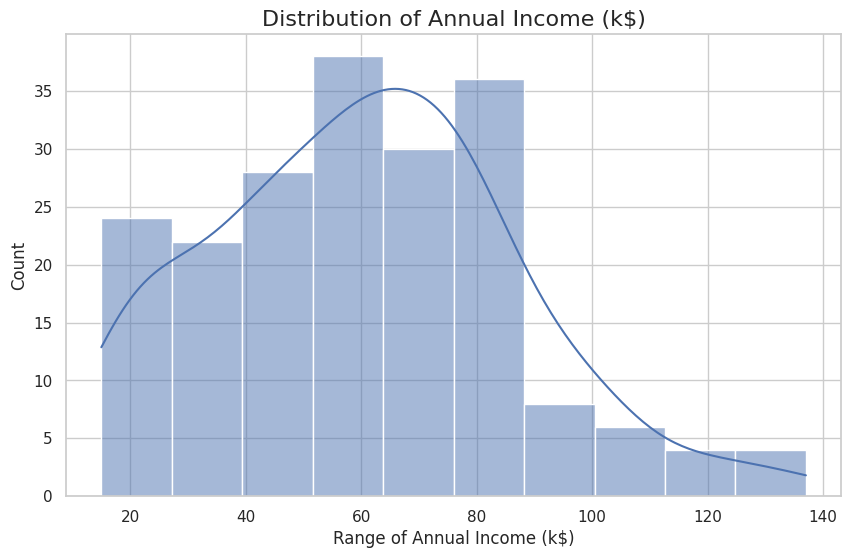

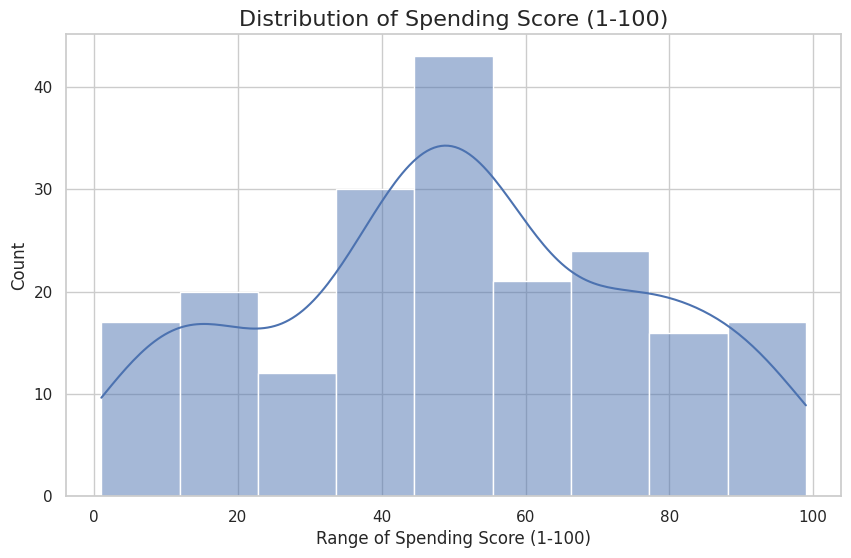

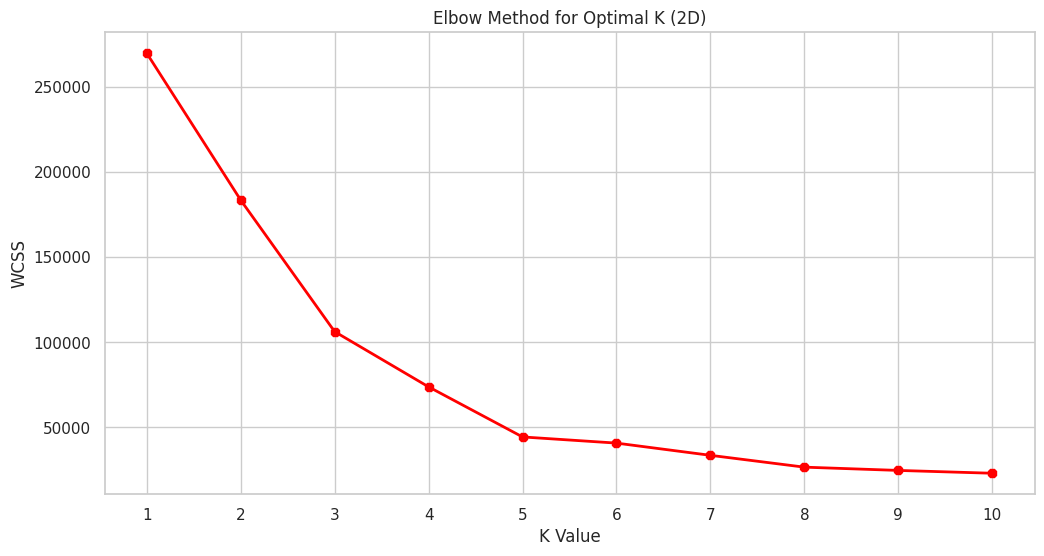

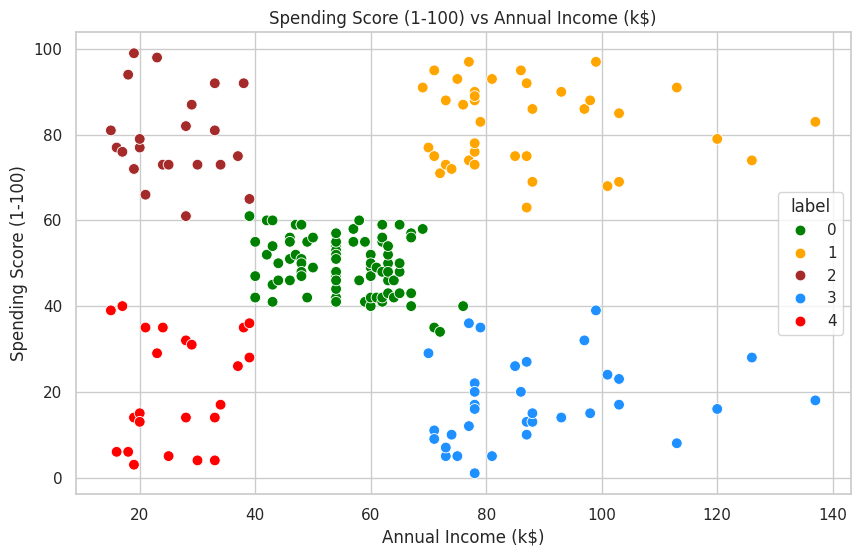

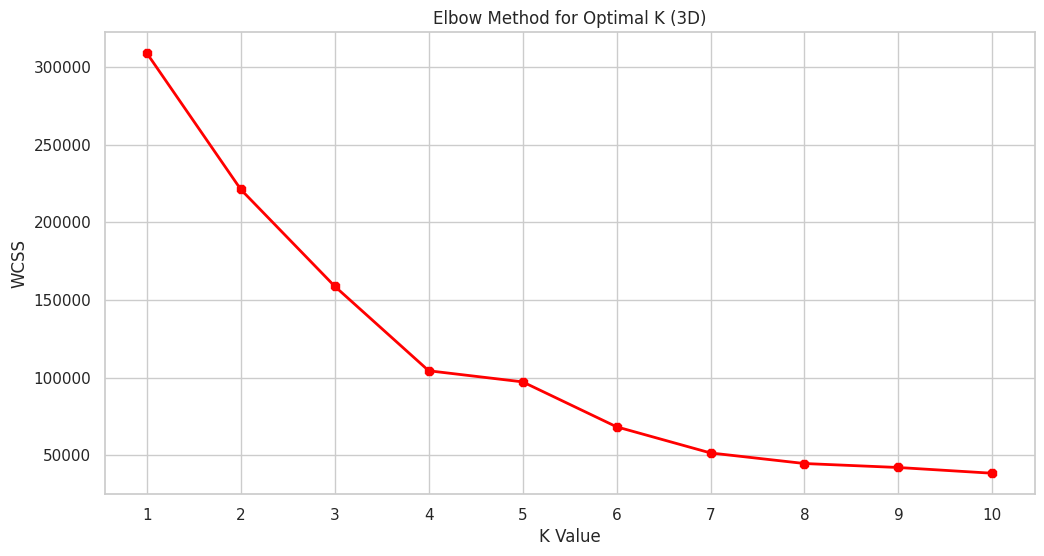

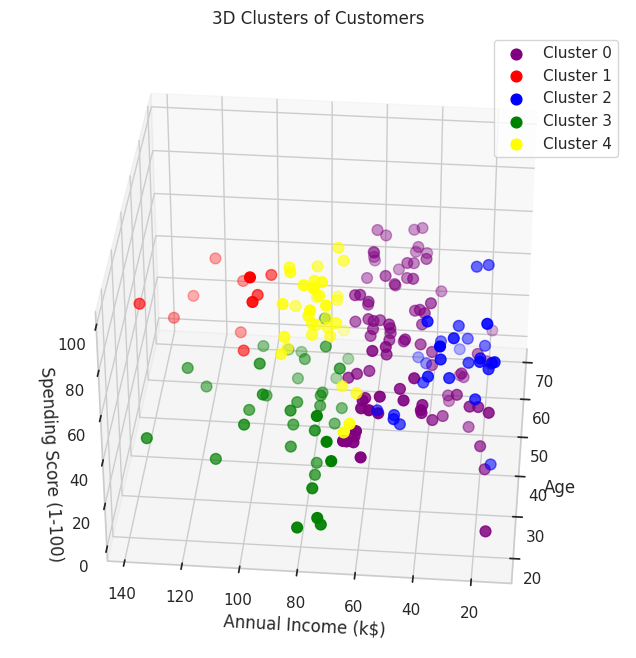

Number of customers in Group 0 = 89
Customer IDs: [  3   5   7   9  11  13  15  17  19  21  23  25  27  29  31  33  35  37
  39  41  43  45  47  48  49  50  51  53  54  55  56  57  58  59  60  61
  63  64  65  67  68  70  71  72  73  74  75  76  77  78  79  80  81  82
  83  84  86  87  88  89  90  91  92  93  94  95  96  97  98  99 100 101
 102 103 105 106 107 108 109 110 111 113 114 115 117 118 119 120 122]
--------------------------------------------------
Number of customers in Group 1 = 11
Customer IDs: [180 182 184 186 188 190 192 194 196 198 200]
--------------------------------------------------
Number of customers in Group 2 = 29
Customer IDs: [ 1  2  4  6  8 10 12 14 16 18 20 22 24 26 28 30 32 34 36 38 40 42 44 46
 52 62 66 69 85]
--------------------------------------------------
Number of customers in Group 3 = 38
Customer IDs: [125 127 129 131 133 135 137 139 141 143 145 147 149 151 153 155 157 159
 161 163 165 167 169 171 173 175 177 179 181 183 185 187 189 191 193 195
 19

In [15]:
# Importing the necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D
from sklearn.cluster import KMeans

# -----------------------------------------------------------
# 1. Reading the Dataset
# -----------------------------------------------------------
# The manual demonstrates clustering using customer spending/income data
# (Mall_Customers.xlsx / sales_data_sample.csv)
# Fixed: Corrected file name to match the file in workspace ('Mall Customers.xlsx')
data = pd.read_excel("Mall Customers.xlsx")

print("First 5 rows:")
print(data.head())

print("\nDataset Correlation:")
print(data.corr(numeric_only=True))

# -----------------------------------------------------------
# 2. Exploratory Data Distribution
# -----------------------------------------------------------
sns.set(style='whitegrid')

# Annual Income Distribution
plt.figure(figsize=(10, 6))
sns.histplot(data['Annual Income (k$)'], kde=True)
plt.title('Distribution of Annual Income (k$)', fontsize=16)
plt.xlabel('Range of Annual Income (k$)')
plt.ylabel('Count')
plt.show()

# Spending Score Distribution
plt.figure(figsize=(10, 6))
sns.histplot(data['Spending Score (1-100)'], kde=True)
plt.title('Distribution of Spending Score (1-100)', fontsize=16)
plt.xlabel('Range of Spending Score (1-100)')
plt.ylabel('Count')
plt.show()

# -----------------------------------------------------------
# 3. K-Means Clustering based on 2 Features (Income & Spending)
# -----------------------------------------------------------
df1 = data[["CustomerID", "Gender", "Age", "Annual Income (k$)", "Spending Score (1-100)"]].copy()
X = df1[["Annual Income (k$)", "Spending Score (1-100)"]]

# Finding optimal K using Within-Cluster Sum of Squares (WCSS / Inertia) - Elbow Method
wcss = []
for i in range(1, 11):
    km = KMeans(n_clusters=i, init="k-means++", random_state=42)
    km.fit(X)
    wcss.append(km.inertia_)

# Plotting the Elbow Curve
plt.figure(figsize=(12, 6))
plt.plot(range(1, 11), wcss, linewidth=2, color="red", marker="8")
plt.xlabel("K Value")
plt.xticks(np.arange(1, 11, 1))
plt.ylabel("WCSS")
plt.title("Elbow Method for Optimal K (2D)")
plt.show()

# Based on the elbow joint, K = 5 is selected
km1 = KMeans(n_clusters=5, init="k-means++", random_state=42)
km1.fit(X)
y = km1.predict(X)
df1["label"] = y

# Scatterplot of 2D Clusters
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue="label",
    palette=['green', 'orange', 'brown', 'dodgerblue', 'red'],
    legend='full',
    data=df1,
    s=60
)
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Spending Score (1-100) vs Annual Income (k$)')
plt.show()

# -----------------------------------------------------------
# 4. K-Means Clustering on 3 Features (Age, Income, Spending)
# -----------------------------------------------------------
df2 = data[["CustomerID", "Gender", "Age", "Annual Income (k$)", "Spending Score (1-100)"]].copy()
X2 = df2[["Age", "Annual Income (k$)", "Spending Score (1-100)"]]

# Elbow method for 3D data
wcss_3d = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, init="k-means++", random_state=42)
    kmeans.fit(X2)
    wcss_3d.append(kmeans.inertia_)

plt.figure(figsize=(12, 6))
plt.plot(range(1, 11), wcss_3d, linewidth=2, color="red", marker="8")
plt.xlabel("K Value")
plt.xticks(np.arange(1, 11, 1))
plt.ylabel("WCSS")
plt.title("Elbow Method for Optimal K (3D)")
plt.show()

# Fitting 3D model with K = 5
km2 = KMeans(n_clusters=5, init="k-means++", random_state=42)
y2 = km2.fit_predict(X2)
df2["label"] = y2

# 3D Cluster Visualization
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')
colors = ['purple', 'red', 'blue', 'green', 'yellow']

for label, col in zip(range(5), colors):
    subset = df2[df2.label == label]
    ax.scatter(subset['Age'], subset['Annual Income (k$)'], subset['Spending Score (1-100)'], c=col, s=60, label=f'Cluster {label}')

ax.view_init(35, 185)
ax.set_xlabel("Age")
ax.set_ylabel("Annual Income (k$)")
ax.set_zlabel('Spending Score (1-100)')
plt.title("3D Clusters of Customers")
plt.legend()
plt.show()

# -----------------------------------------------------------
# 5. Customer IDs per Cluster Group
# -----------------------------------------------------------
for group_id in range(5):
    cust_group = df2[df2["label"] == group_id]
    print(f"Number of customers in Group {group_id} = {len(cust_group)}")
    print("Customer IDs:", cust_group["CustomerID"].values)
    print("-" * 50)